Saved 2020!
Saved 2021!
Saved 2022!
Saved 2023!

All weather data downloaded and saved!


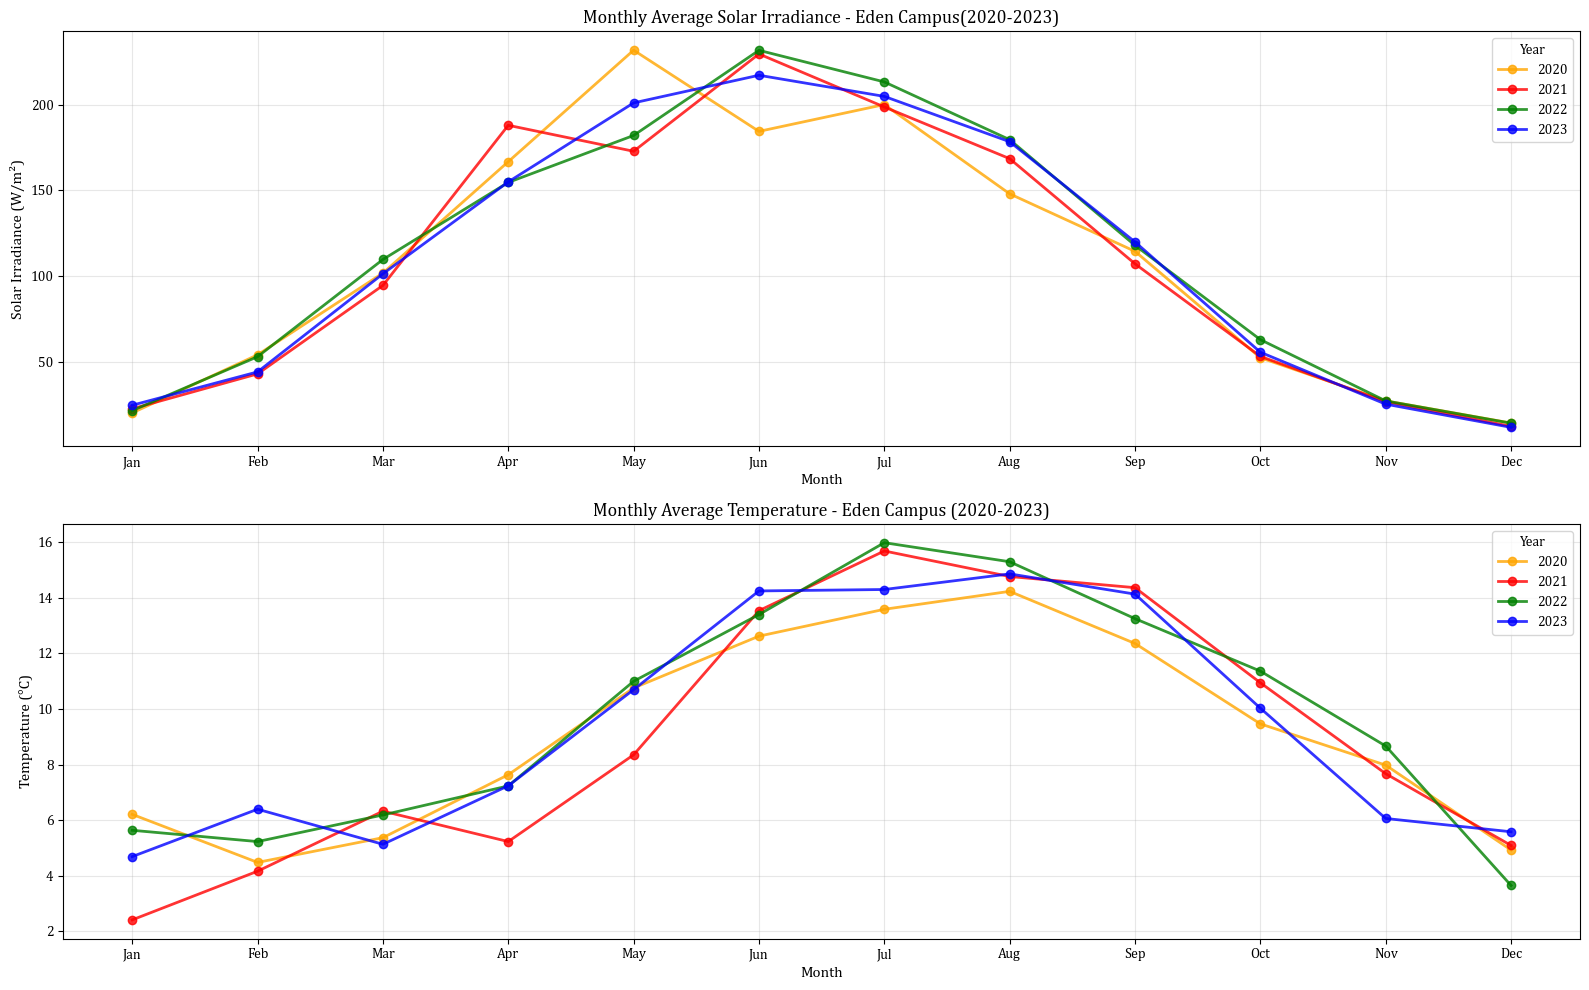

Weather plot saved!


In [2]:
import pvlib
import pandas as pd
import matplotlib.pyplot as plt
import os

plt.rcParams['font.family'] = 'Cambria'

base      = os.path.join(os.path.expanduser("~"), "Documents", "EdenCampus_PhD")
latitude  = 56.3398
longitude = -2.7967
years     = [2020, 2021, 2022, 2023]
all_years = {}

for year in years:
    print(f"Downloading {year}...")
    result = pvlib.iotools.get_pvgis_hourly(
        latitude=latitude,
        longitude=longitude,
        start=year, end=year,
        map_variables=True
    )
    data = result[0]
    all_years[year] = data
    save_path = os.path.join(base, "01_data/weather", f"eden_campus_{year}.csv")
    data.to_csv(save_path)
    print(f"Saved {year}!")

print("\nAll weather data downloaded and saved!")

# ── Plot all years ──
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
colors = ['orange', 'red', 'green', 'blue']
months = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

for (year, data), color in zip(all_years.items(), colors):
    data['total_irradiance'] = (data['poa_direct'] +
                                 data['poa_sky_diffuse'] +
                                 data['poa_ground_diffuse'])
    monthly_irr = data['total_irradiance'].resample('ME').mean()
    axes[0].plot(range(1, len(monthly_irr) + 1), monthly_irr.values,
                 color=color, marker='o', linewidth=2,
                 markersize=6, label=str(year), alpha=0.8)

axes[0].set_title('Monthly Average Solar Irradiance - Eden Campus(2020-2023)',
                   fontsize=13, fontfamily='Cambria')
axes[0].set_ylabel('Solar Irradiance (W/m²)', fontsize=11, fontfamily='Cambria')
axes[0].set_xlabel('Month', fontsize=11, fontfamily='Cambria')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(months, fontfamily='Cambria', fontsize=10)
for label in axes[0].get_yticklabels():
    label.set_fontfamily('Cambria')
axes[0].legend(title='Year', prop={'family':'Cambria','size':10},
               title_fontproperties={'family':'Cambria','size':10})
axes[0].grid(True, alpha=0.3)

for (year, data), color in zip(all_years.items(), colors):
    monthly_temp = data['temp_air'].resample('ME').mean()
    axes[1].plot(range(1, len(monthly_temp) + 1), monthly_temp.values,
                 color=color, marker='o', linewidth=2,
                 markersize=6, label=str(year), alpha=0.8)

axes[1].set_title('Monthly Average Temperature - Eden Campus (2020-2023)',
                   fontsize=13, fontfamily='Cambria')
axes[1].set_ylabel('Temperature (°C)', fontsize=11, fontfamily='Cambria')
axes[1].set_xlabel('Month', fontsize=11, fontfamily='Cambria')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(months, fontfamily='Cambria', fontsize=10)
for label in axes[1].get_yticklabels():
    label.set_fontfamily('Cambria')
axes[1].legend(title='Year', prop={'family':'Cambria','size':10},
               title_fontproperties={'family':'Cambria','size':10})
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(base, "01_data/weather", "eden_campus_monthly_by_year.png")
plt.savefig(save_path, dpi=150)
plt.show()
print("Weather plot saved!")